In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

# Data

In [2]:
# load data
SP500_df = pd.read_csv('SP500.csv')

# take log-diffs and drop nans
SP500_df['log_returns'] = SP500_df['SP500'].apply(lambda x: np.log(x)).diff()

# set index
SP500_df['observation_date'] = pd.DatetimeIndex(SP500_df['observation_date'])
SP500_df = SP500_df.set_index('observation_date')

# print dates
print(f'Data from {SP500_df.index[0]} to {SP500_df.index[-1]}')

# drop nans -> inspect which is nans
SP500_df = SP500_df.dropna()

Data from 2016-09-19 00:00:00 to 2026-09-17 00:00:00


# Simulating Heston for S&P500 prices

In [3]:
seed = 42
np.random.seed(seed)

In [4]:
def draw_dWs(rho, dt, N=1):

    # draw normals
    N1 = np.random.normal(size=(N))
    N2 = np.random.normal(size=(N))

    # setup BMs
    dW1 = np.sqrt(dt) * N1
    dW2 = rho * dW1 + np.sqrt(1-rho**2) * np.sqrt(dt) * N2

    return dW1, dW2

def full_trunc_euler(S0, mu, kappa, theta, sigma_V, rho, Nsteps, V0=None, N=1, T=1):

    dt = T/Nsteps

    # allocate
    V = np.zeros((Nsteps, N)) + np.nan
    S = np.zeros((Nsteps, N)) + np.nan
    Y = np.zeros((Nsteps, N)) + np.nan
    Y_diff = np.zeros((Nsteps-1, N)) + np.nan

    # initialize logged stock price
    Yt = np.log(np.ones(N)*S0) # (N,)

    # specified initial variance
    if V0 is not None:
        Vt = np.ones(N)*V0 # (N,)

    # draw from ergodic distributoon
    else:

        # CIR parameters
        omega_CIR = (2*kappa)/(sigma_V**2)
        nu_CIR = (2*kappa*theta)/(sigma_V**2)

        # Gamma dist parameters
        shape_Gamma = nu_CIR
        scale_Gamma = 1/omega_CIR

        Vt = np.random.gamma(shape=shape_Gamma, scale=scale_Gamma, size=(N)) # (N,)

    for i in range(Nsteps):

        # draw Brownian motions
        dW1, dW2 = draw_dWs(rho, dt, N=N)

        # simulate logged stock price
        Vtpos = np.maximum(Vt, 0.00)
        Yt = Yt + (mu-0.5*Vtpos) * dt + np.sqrt(Vtpos) * dW1

        # simulate instantenous variance
        Vt = Vt + kappa * (theta - Vtpos) * dt + sigma_V * np.sqrt(Vtpos) * dW2

        # save
        V[i] = Vt
        Y[i] = Yt

        if i > 0:
            Y_diff[i-1] = Y[i] - Y[i-1]

    return S, V, Y, Y_diff

In [76]:
T = 10
Nsteps = 252*T # per day
N = 20000
dt = T/Nsteps

S0 = 1.0

mu = SP500_df['log_returns'].mean().item()/dt # mean is daily mean, mu is mean for one period, i.e. one year

theta = SP500_df['log_returns'].var()/dt
V0 = theta
kappa = 2.00
sigma_V = 0.36 #0.297
rho = -0.5

print(f'Feller is fulfilled: {2*kappa*theta > sigma_V**2}')
print(f'2 kappa theta = {2*kappa*theta}')
print(f'sigma_V^2 = {sigma_V**2}')

Feller is fulfilled: True
2 kappa theta = 0.1319775980928147
sigma_V^2 = 0.1296


In [85]:
SP500_df['log_returns'].var()

0.00013093015683810982

In [77]:
# # parameters defined in CIR paper used to derive ergodic Gamma dist. for volatility
# omega_CIR = (2*kappa)/(sigma_V**2)
# nu_CIR = (2*kappa*theta)/(sigma_V**2)

# shape_Gamma = nu_CIR
# scale_Gamma = 1/omega_CIR

# # plot
# f, ax = plt.subplots()
# x = np.linspace(0,0.5,1000)
# ax.plot(x,stats.gamma.pdf(x, a=shape_Gamma, scale=scale_Gamma), label='pdf')
# ax.vlines(shape_Gamma*scale_Gamma, 0.00, 20.0, ls='--', color='red', label='mean')
# ax.set_xlabel('V')
# ax.set_ylabel('Density')
# ax.legend()

In [78]:
# # draw volatility from ergodic distribution
# V_draws = np.random.gamma(shape=shape_Gamma, scale=scale_Gamma, size=(N))

# # draw brownian motions
# dW1s = np.sqrt(dt) * np.random.normal(size=(N))

# # draw Xs
# dX_draws = (mu-0.5*V_draws)*dt + np.sqrt(V_draws)*dW1s

In [79]:
S_sim, V_sim, Y_sim, Y_diff_sim = full_trunc_euler(S0, mu, kappa, theta, sigma_V, rho, Nsteps, N=N, T=T)

# S&P500 log-returns

Sample mean = 0.00057
Sample std. = 0.01144


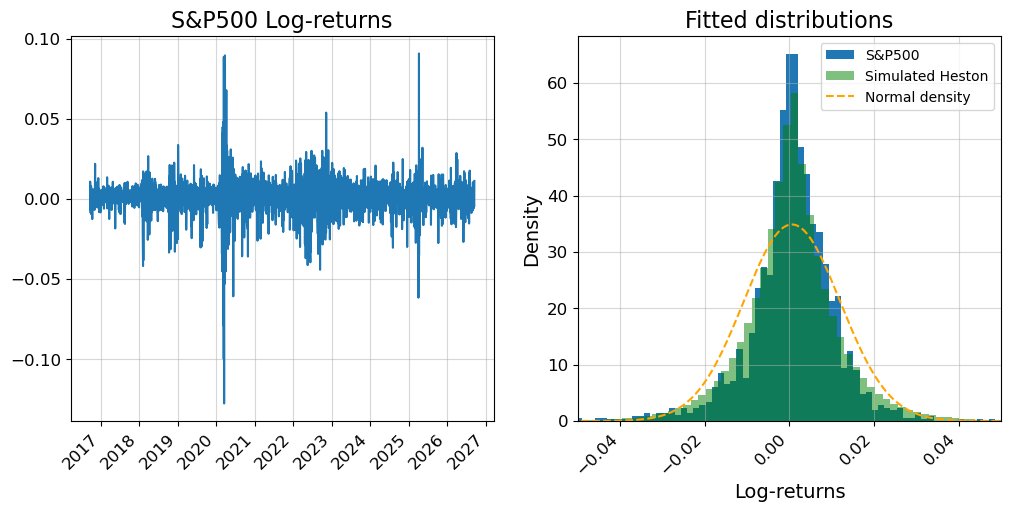

In [80]:
plt.rcParams.update({
    'font.size': 13,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 10
})

f, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].plot(SP500_df.index, SP500_df['log_returns'])
ax[0].set_title('S&P500 Log-returns')
#ax[0].grid()

ax[1].hist(SP500_df['log_returns'], bins=150, density=True, label='S&P500')
ax[1].hist(Y_diff_sim.flatten(), bins=150, density=True, alpha=0.5, label='Simulated Heston', color='green')
x_ = np.linspace(SP500_df['log_returns'].min(), SP500_df['log_returns'].max(), 1000)
norm_pdf = stats.norm.pdf(x_, loc=SP500_df['log_returns'].mean().item(), scale=SP500_df['log_returns'].std())
ax[1].plot(x_, norm_pdf, label='Normal density', color='orange', ls='--')

ax[1].set_xlabel('Log-returns')
ax[1].set_ylabel('Density')
ax[1].set_xlim([-0.05, 0.05])
ax[1].set_title('Fitted distributions')
ax[1].legend()

for i in range(2):
    plt.setp(ax[i].get_xticklabels(), rotation=45, ha='right')
    ax[i].grid(alpha=0.5)

print(f'Sample mean = {SP500_df['log_returns'].mean().item():.5f}')
print(f'Sample std. = {SP500_df['log_returns'].std():.5f}')

f.savefig('SP500.png')